# PyG HeteroData export

`to_pyg` exports an AnnNet graph to a
[`HeteroData`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.data.HeteroData.html)
object of [PyTorch Geometric](https://pyg.org/) (PyG), the input of graph neural
network models. Each node kind becomes a node type, and the numeric attributes
that you select become the feature tensors.

To run this notebook, create the environment from
[`pyg-heterodata-export.yml`](environments/pyg-heterodata-export.yml). See
[Reproduce a tutorial](index.md#reproduce-a-tutorial).

## Build a heterogeneous graph

The graph has three node kinds: proteins, a gene and a drug. Each kind has its
own numeric attributes. The `train` slice contains two of the edges and their
nodes.

In [1]:
import annnet as an

anet = an.AnnNet(directed=True)
anet.add_nodes('p1', kind='protein', activity=1.2, abundance=4.0)
anet.add_nodes('p2', kind='protein', activity=-0.4, abundance=2.5)
anet.add_nodes('g1', kind='gene', expression=8.0, length=1200.0)
anet.add_nodes('drug_a', kind='drug', dosage=10.0, approved=1.0)

anet.add_edges('p1', 'g1', edge_id='regulates', weight=0.8)
anet.add_edges('p2', 'g1', edge_id='represses', weight=-0.6)
anet.add_edges('drug_a', 'p1', edge_id='targets', weight=0.5)
anet.add_edges('drug_a', 'p2', edge_id='off_target', weight=0.25)
anet.slices.add('train')
anet.slices.add_edges('train', ['regulates', 'represses'])

anet.attrs.table('nodes', derived=True)

node_id,kind,activity,abundance,expression,length,dosage,approved
str,str,f64,f64,f64,f64,f64,f64
"""p1""","""protein""",1.2,4.0,null,null,null,null
"""p2""","""protein""",-0.4,2.5,null,null,null,null
"""g1""","""gene""",null,null,8.0,1200.0,null,null
"""drug_a""","""drug""",null,null,null,null,10.0,1.0


## Draw the source graph


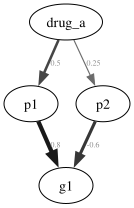

In [2]:
from annnet.utils import plotting

plotting.plot(anet, backend='graphviz', show_edge_labels=True)

## Export to PyG and run a tensor operation

`node_features` lists, for each node kind, the attributes that become the
columns of the feature matrix `x`. For each node type, `train_mask` marks the
nodes of the `train` slice.

In [3]:
import torch

data = an.to_pyg(
    anet,
    node_features={
        'protein': ['activity', 'abundance'],
        'gene': ['expression', 'length'],
        'drug': ['dosage', 'approved'],
    },
    slice_id='train',
    hyperedge_mode='skip',
)
data.validate(raise_on_error=True)

protein_activity = data['protein'].x[:, 0]
activity_probability = torch.sigmoid(protein_activity)
homogeneous = data.to_homogeneous()

print(data)
print('protein activity:', protein_activity.tolist())
print('sigmoid(activity):', activity_probability.tolist())
print('homogeneous edge_index shape:', tuple(homogeneous.edge_index.shape))

HeteroData(
  manifest={
    node_index={
      protein={
        p1=0,
        p2=1,
      },
      gene={ g1=0 },
      drug={ drug_a=0 },
    },
    edge_index={
      protein|edge|gene=[2],
      drug|edge|protein=[2],
    },
  },
  protein={
    x=[2, 2],
    train_mask=[2],
  },
  gene={
    x=[1, 2],
    train_mask=[1],
  },
  drug={
    x=[1, 2],
    train_mask=[1],
  },
  (protein, edge, gene)={
    edge_index=[2, 2],
    edge_weight=[2],
  },
  (drug, edge, protein)={
    edge_index=[2, 2],
    edge_weight=[2],
  }
)
protein activity: [1.2000000476837158, -0.4000000059604645]
sigmoid(activity): [0.7685248255729675, 0.40131235122680664]
homogeneous edge_index shape: (2, 4)


/tmp/claude-1000/-home-denes-saezverse/017de654-b22d-4c6c-bfa4-a9b9694cd0d2/scratchpad/nbenv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


AnnNet is useful before the conversion to tensors: it stores the names, the
metadata, the slices and the graph semantics. `to_pyg` is the boundary where the
selected numeric attributes become tensors.